# Module 02: Exploratory Data Analysis & Visualizations
## Project: Electric Vehicle (EV) Population Analysis

### Overview:
In this notebook, we analyze the cleaned EV dataset (`ev_cleaned.csv`). We evaluate market growth trends across model years, manufacturer dominance, electric powertrain preferences (BEV vs. PHEV), driving range patterns, and geographic distribution across Washington State.

### import libraries and load cleaned EV dataset

In [3]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy import stats

# load the cleaned EV dataset created in module 1

df = pd.read_csv("../data/ev_cleaned_dataset.csv")

df.head()

,county,city,state,postal_code,model_year,make,model,electric_vehicle_type,clean_alternative_fuel_vehicle_(cafv)_eligibility,electric_range,base_msrp,electric_utility,powertrain,adoption_era,range_category
0,King,Seattle,WA,98103.0,2020,HYUNDAI,KONA,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,258,0,CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),BEV,Transition Phase (2017-2020),Long Range (>200 mi)
1,King,Bothell,WA,98011.0,2022,JEEP,GRAND CHEROKEE,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25,0,PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),PHEV,Mass Market (2021-Present),Short Range (<100 mi)
2,Yakima,Yakima,WA,98908.0,2023,JEEP,GRAND CHEROKEE,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25,0,PACIFICORP,PHEV,Mass Market (2021-Present),Short Range (<100 mi)
3,King,Kirkland,WA,98034.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215,0,PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),BEV,Transition Phase (2017-2020),Long Range (>200 mi)
4,Thurston,Olympia,WA,98501.0,2018,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,97,0,PUGET SOUND ENERGY INC,PHEV,Transition Phase (2017-2020),Short Range (<100 mi)


### Yearly EV Adoption trend

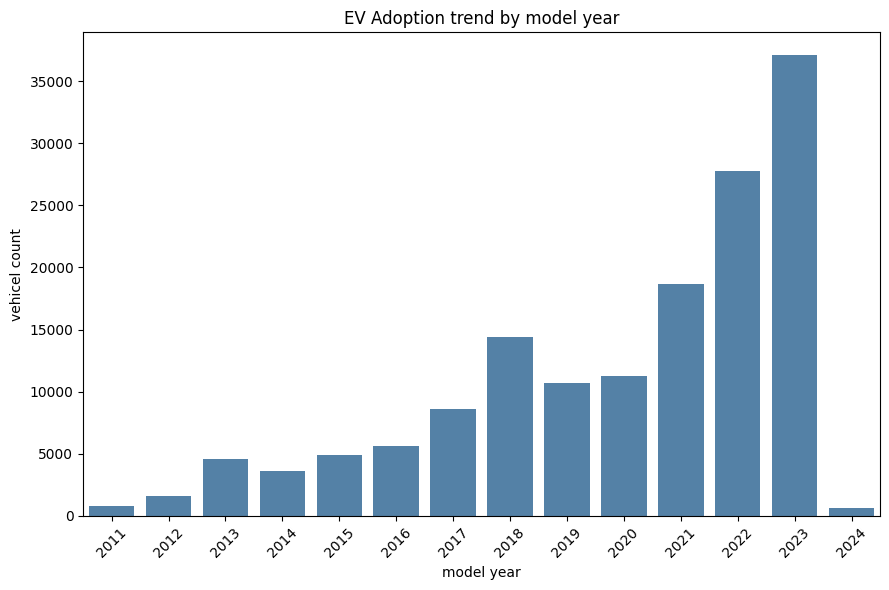

In [4]:
plt.figure(figsize=(9,6))

# count vehicels per model years 
sns.countplot(data=df, x="model_year", color='steelblue')
plt.title("EV Adoption trend by model year")
plt.xlabel("model year")
plt.ylabel("vehicel count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../images/01_adoption_trend_by_years.png",dpi=300)
plt.show()

### Top 10 EV Manufactures 

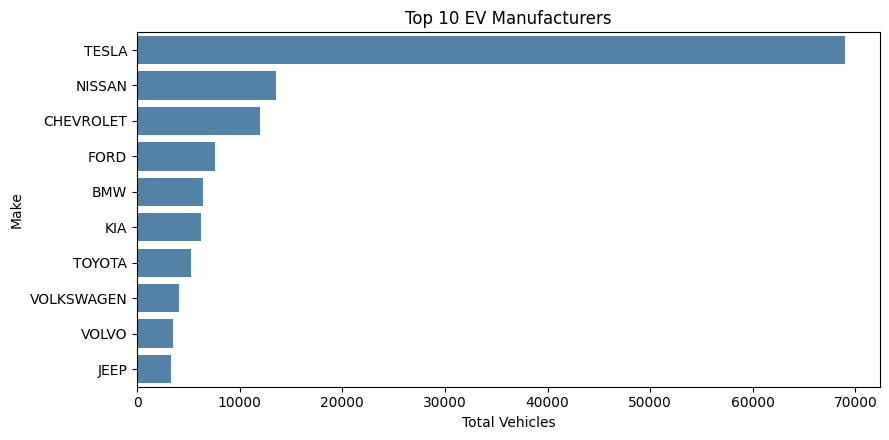

In [5]:
plt.figure(figsize=(9, 4.5))

# Top 10 makes
top_10_makes = df['make'].value_counts().head(10).index

# Countplot for top 10 makers
sns.countplot(data=df, y='make', order=top_10_makes, color="steelblue")

plt.title("Top 10 EV Manufacturers")
plt.xlabel("Total Vehicles")
plt.ylabel("Make")

plt.tight_layout()
plt.savefig('../images/02_top_10_manufacturers.png', dpi=300)
plt.show()

### EV type Distribution(BEV vs PHEV)

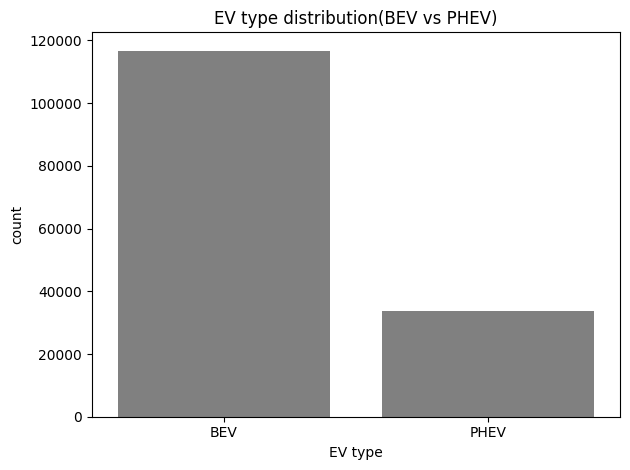

In [6]:
plt.Figure(figsize=(9,4.5))

sns.countplot(data=df, x="powertrain",color="gray")
plt.title("EV type distribution(BEV vs PHEV)")
plt.xlabel("EV type")
plt.ylabel("count")
plt.tight_layout()
plt.savefig("../images/03_ev_type_distribution.png",dpi=300)
plt.show()


### Electric Driving Range Distribution

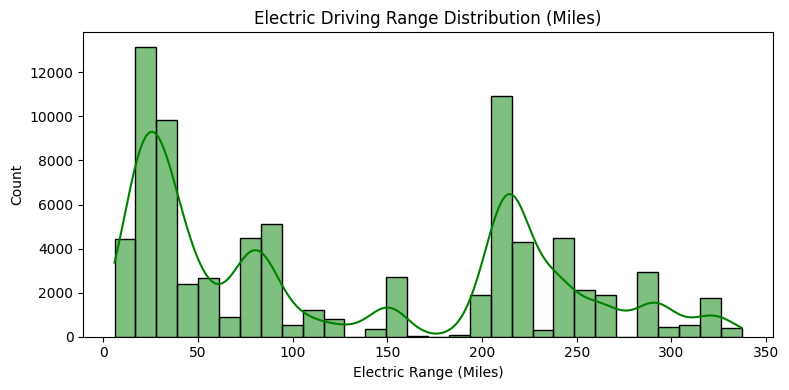

In [7]:
plt.figure(figsize=(8, 4))

# Filter vehicles having recorded range (> 0)
range_data = df[df['electric_range'] > 0]

# Simple histogram with KDE
sns.histplot(data=range_data, x='electric_range', kde=True, color='green', bins=30)

plt.title("Electric Driving Range Distribution (Miles)")
plt.xlabel("Electric Range (Miles)")
plt.ylabel("Count")

plt.tight_layout()
plt.savefig('../images/04_electric_range_distributions.png', dpi=300)
plt.show()

### Top 8 Counties with Highest EV Registrations

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_22012\124403579.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='county', order=top_8_counties, palette='viridis')


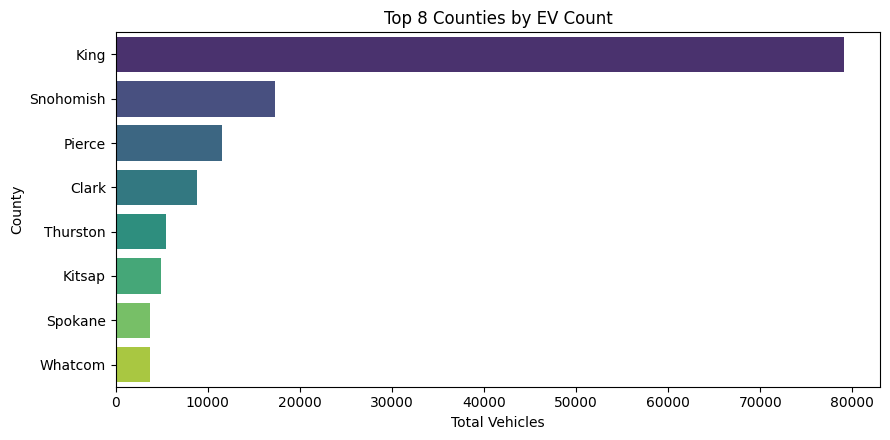

In [18]:
plt.figure(figsize=(9, 4.5))

# Top 8 counties
top_8_counties = df['county'].value_counts().head(8).index

# Plot horizontal bar chart
sns.countplot(data=df, y='county', order=top_8_counties, palette='viridis')

plt.title("Top 8 Counties by EV Count")
plt.xlabel("Total Vehicles")
plt.ylabel("County")

plt.tight_layout()
plt.savefig('../images/05_geographic_distribution.png', dpi=300)
plt.show()

### Powertrain Adoption Across Eras

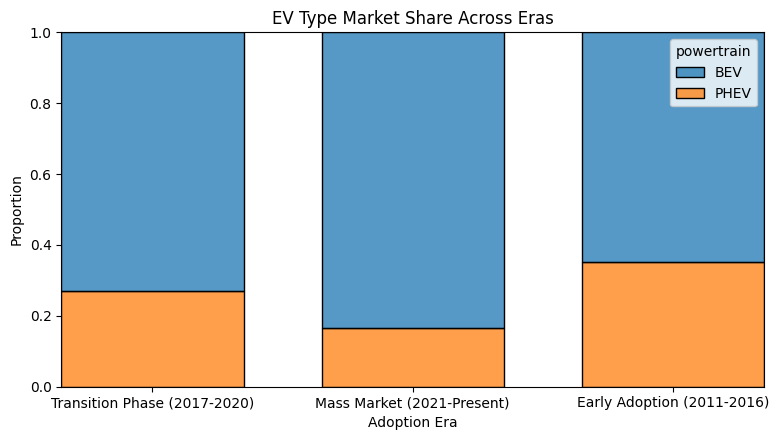

In [9]:
plt.figure(figsize=(8, 4.5))

# Direct Seaborn: era vs ev_type
sns.histplot(
    data=df, 
    x='adoption_era', 
    hue='powertrain', 
    multiple='fill', 
    stat='percent',
    shrink=0.7,
    palette=['#1f77b4', '#ff7f0e']
)

plt.title("EV Type Market Share Across Eras")
plt.xlabel("Adoption Era")
plt.ylabel("Proportion")

plt.tight_layout()
plt.savefig('../images/06_powertrain_era_transition.png', dpi=300)
plt.show()

### Hypothesis Testing (BEV vs. PHEV Electric Range)

In [10]:
# Filter vehicles with recorded electric range (> 0)
range_df = df[df['electric_range'] > 0]

bev_range = range_df[range_df['powertrain'] == 'BEV']['electric_range']
phev_range = range_df[range_df['powertrain'] == 'PHEV']['electric_range']

# Mann-Whitney U Test (Independent 2-sample test)
u_stat, p_value = stats.mannwhitneyu(bev_range, phev_range)

print(f"BEV Median Range: {bev_range.median():.1f} miles")
print(f"PHEV Median Range: {phev_range.median():.1f} miles")
print(f"P-Value: {p_value:.5e}")

if p_value < 0.05:
    print("Conclusion: Significant statistical difference between BEV and PHEV ranges.")

BEV Median Range: 215.0 miles
PHEV Median Range: 26.0 miles
P-Value: 0.00000e+00
Conclusion: Significant statistical difference between BEV and PHEV ranges.


### Comparative Range Distribution (KDE + Boxplot)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_22012\3929206160.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=range_df, x='powertrain', y='electric_range', palette=['#1f77b4', '#ff7f0e'], ax=axes[1], width=0.5)


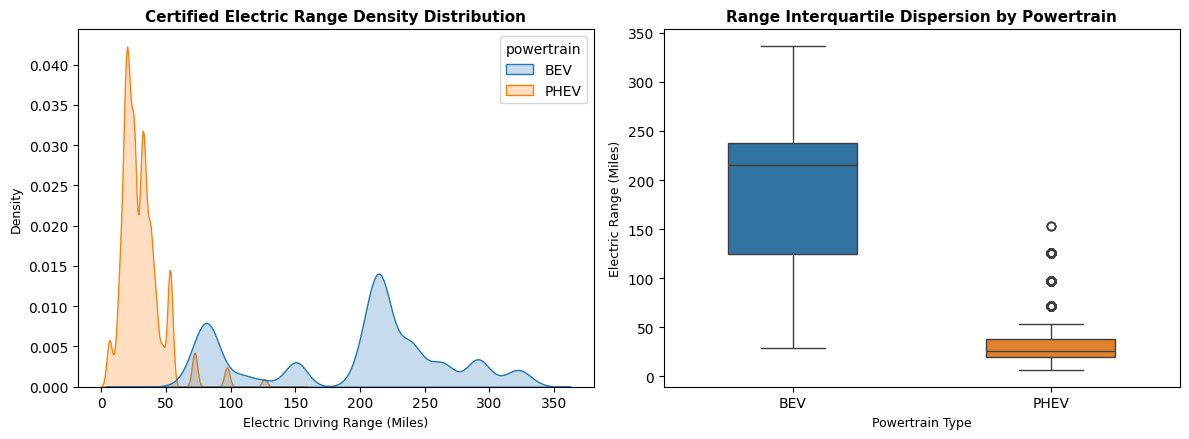

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Kernel Density Estimate Plot
sns.kdeplot(data=range_df, x='electric_range', hue='powertrain', fill=True, common_norm=False, palette=['#1f77b4', '#ff7f0e'], ax=axes[0])
axes[0].set_title("Certified Electric Range Density Distribution", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Electric Driving Range (Miles)", fontsize=9)
axes[0].set_ylabel("Density", fontsize=9)

# 2. Boxplot comparing BEV vs PHEV
sns.boxplot(data=range_df, x='powertrain', y='electric_range', palette=['#1f77b4', '#ff7f0e'], ax=axes[1], width=0.5)
axes[1].set_title("Range Interquartile Dispersion by Powertrain", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Powertrain Type", fontsize=9)
axes[1].set_ylabel("Electric Range (Miles)", fontsize=9)

plt.tight_layout()
plt.savefig('../images/07_bev_vs_phev_range_comparison.png', dpi=300)
plt.show()

### Top Manufacturer Battery Range Performance

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_22012\1142641960.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


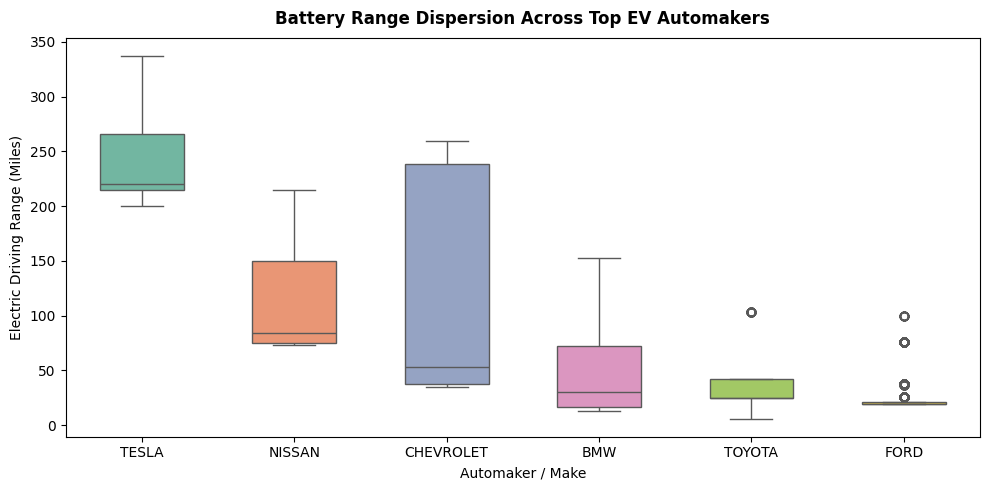

Median Electric Range by Automaker (Miles):
make
TESLA        220.0
NISSAN        84.0
CHEVROLET     53.0
BMW           30.0
TOYOTA        25.0
FORD          19.0
Name: electric_range, dtype: float64


In [15]:
# Identify top 6 manufacturers with recorded electric range records
top_range_makes = range_df['make'].value_counts().head(6).index
top_range_df = range_df[range_df['make'].isin(top_range_makes)]

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=top_range_df, 
    x='make', 
    y='electric_range', 
    order=top_range_makes, 
    palette='Set2', 
    width=0.55
)

plt.title("Battery Range Dispersion Across Top EV Automakers", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Automaker / Make", fontsize=10)
plt.ylabel("Electric Driving Range (Miles)", fontsize=10)

plt.tight_layout()
plt.savefig('../images/08_manufacturer_range_dispersion.png', dpi=300)
plt.show()

# Print exact median range per top automaker
print("Median Electric Range by Automaker (Miles):")
print(top_range_df.groupby('make')['electric_range'].median().loc[top_range_makes])

### Range Category Progression by Era

<Figure size 900x450 with 0 Axes>

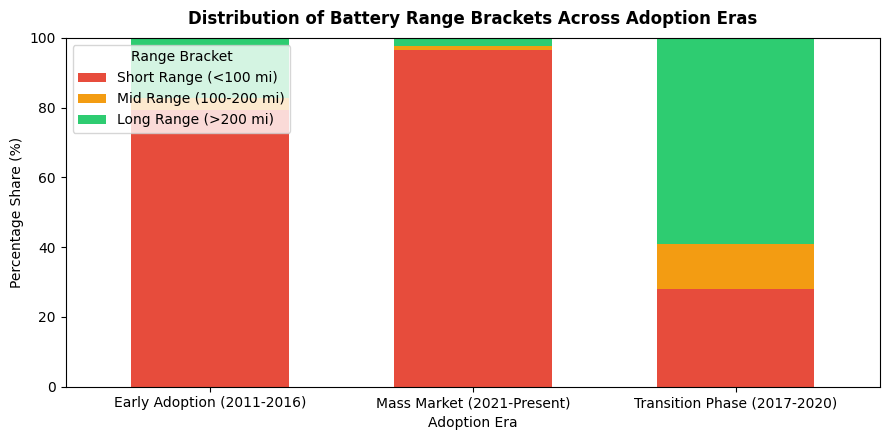

In [16]:
# Filter out unrecorded ranges to inspect verified battery bracket evolution
recorded_era_df = df[df['range_category'] != 'Unrecorded / Not Certified']
era_brackets = pd.crosstab(recorded_era_df['adoption_era'], recorded_era_df['range_category'], normalize='index') * 100

# Desired column order
bracket_order = ['Short Range (<100 mi)', 'Mid Range (100-200 mi)', 'Long Range (>200 mi)']
era_brackets = era_brackets[[c for c in bracket_order if c in era_brackets.columns]]

plt.figure(figsize=(9, 4.5))
era_brackets.plot(
    kind='bar', 
    stacked=True, 
    color=['#e74c3c', '#f39c12', '#2ecc71'], 
    figsize=(9, 4.5), 
    width=0.6
)

plt.title("Distribution of Battery Range Brackets Across Adoption Eras", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Adoption Era", fontsize=10)
plt.ylabel("Percentage Share (%)", fontsize=10)
plt.legend(title="Range Bracket", loc="upper left")
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.tight_layout()
plt.savefig('../images/09_battery_bracket_evolution.png', dpi=300)
plt.show()